# Семинар 1. Интерполяция сплайнами (версия преподавателя)

**Курс «Численные методы», 2 курс бакалавриата**

**План семинара**

1. Задача интерполяции. Глобальная и локальная интерполяция
2. Глобальная интерполяция многочленом Ньютона и феномен Рунге
3. Как бороться с феноменом Рунге: узлы Чебышёва и локальная интерполяция
4. Кусочно-линейная интерполяция
5. Кубический сплайн: определение, граничные условия, свойства
6. Вывод системы для моментов и её свойства
7. Реализация естественного сплайна и сравнение со `scipy`
8. Метод прогонки
9. Исследование сходимости

> 🧑‍🏫 **Для преподавателя.** Ориентировочный тайминг (90 минут):
> - 0–5 мин — разделы 1 (постановка задачи);
> - 5–15 мин — раздел 2 (Ньютон, Рунге), live;
> - 15–22 мин — разделы 3–4 (Чебышёв, кусочно-линейная, локальность), live;
> - 22–40 мин — разделы 5–6 (теория сплайнов, вывод системы);
> - 40–55 мин — раздел 7 (реализация сплайна, scipy), live;
> - 55–60 мин — раздел 8 (теория прогонки);
> - 60–85 мин — задачи 1–2 (студенты), дополнительные задачи для быстрых;
> - 85–90 мин — итоги и домашнее задание.
> 
> Если отстаёте от графика, в первую очередь сокращайте: сгущение узлов через tanh, график производной кусочно-линейной интерполяции, подробный вывод формулы (раздел 6 можно пролистать, акцентируя только итоговую систему).
> 
> Перед парой: перезапустите ядро и прогоните блокнот целиком, увеличьте шрифт в браузере (Ctrl + «+»).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True

## 1. Задача интерполяции

Пусть на отрезке $[a, b]$ заданы узлы $a = x_0 < x_1 < \dots < x_n = b$ и значения $y_i = f(x_i)$. Требуется построить функцию $g(x)$ из некоторого заданного класса, которая проходит через все точки:

$$g(x_i) = y_i, \qquad i = 0, 1, \dots, n.$$

Откуда берутся такие задачи:
- данные эксперимента или справочные таблицы (например, теплофизические свойства вещества при разных температурах);
- функция, вычисление которой очень дорого (результат другого расчёта);
- нужно вычислять значения, производные или интегралы между узлами.

Существуют два принципиально разных подхода.

**Глобальная интерполяция.** Одна функция на всём отрезке, например многочлен степени $n$, проходящий через все $n+1$ точек.

**Локальная (кусочная) интерполяция.** На каждом отрезке $[x_{i-1}, x_i]$ строится своя простая функция, использующая только соседние узлы.

## 2. Глобальная интерполяция: многочлен Ньютона

Напомним, что интерполяционный многочлен степени $n$ по $n+1$ точкам существует и единственен. Его удобно записывать в форме Ньютона:

$$P_n(x) = f[x_0] + f[x_0, x_1](x - x_0) + f[x_0, x_1, x_2](x - x_0)(x - x_1) + \dots + f[x_0, \dots, x_n]\prod_{k=0}^{n-1}(x - x_k),$$

где разделённые разности определяются рекуррентно:

$$f[x_i] = y_i, \qquad f[x_i, \dots, x_{i+k}] = \frac{f[x_{i+1}, \dots, x_{i+k}] - f[x_i, \dots, x_{i+k-1}]}{x_{i+k} - x_i}.$$

Коэффициенты $c_k = f[x_0, \dots, x_k]$ вычисляются по таблице разделённых разностей «на месте» (в одном массиве), а значение многочлена — по схеме Горнера:

$$P_n(x) = c_0 + (x - x_0)\Big(c_1 + (x - x_1)\big(c_2 + \dots + (x - x_{n-1})c_n\big)\Big).$$

In [2]:
def newton_coeff(x, y):
    # Коэффициенты многочлена Ньютона c_k = f[x_0, ..., x_k]
    n = len(x)
    c = np.array(y, dtype=float)
    for k in range(1, n):
        # после шага k в c[i] (i >= k) лежит f[x_{i-k}, ..., x_i]
        c[k:] = (c[k:] - c[k-1:n-1]) / (x[k:] - x[:n-k])
    return c


def newton_eval(c, x, t):
    # Значение многочлена Ньютона в точках t (схема Горнера)
    n = len(x) - 1
    p = c[n] * np.ones_like(t, dtype=float)
    for k in range(n - 1, -1, -1):
        p = p * (t - x[k]) + c[k]
    return p


# Проверка: для f(x) = x^3 по узлам 0, 1, 2, 3 должно быть c = [0, 1, 3, 1]
xs = np.array([0.0, 1.0, 2.0, 3.0])
print(newton_coeff(xs, xs**3))

[0. 1. 3. 1.]


> 🧑‍🏫 **Для преподавателя.** Эти функции можно не писать вживую: студенты проходили форму Ньютона на лекции. Если время есть, напишите `newton_eval` вживую — схема Горнера короткая и наглядная. В вашем исходном блокноте был другой, тоже корректный вариант рекурсии (`c[i:] = (c[i:] - c[i-1]) / (x[i:] - x[i-1])`, он работает благодаря симметрии разделённых разностей). Здесь взят классический вариант, совпадающий с таблицей из учебника.

### Функция Рунге

Рассмотрим функцию

$$f(x) = \frac{1}{1 + 25x^2}, \qquad x \in [-1, 1].$$

Она бесконечно гладкая и выглядит вполне безобидно. Проинтерполируем её многочленом по равноотстоящим узлам и будем увеличивать число узлов. Интуиция подсказывает, что чем больше узлов, тем точнее приближение. Проверим.

In [3]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

a, b = -1.0, 1.0
t = np.linspace(a, b, 2001)   # мелкая сетка для графиков и оценки погрешности

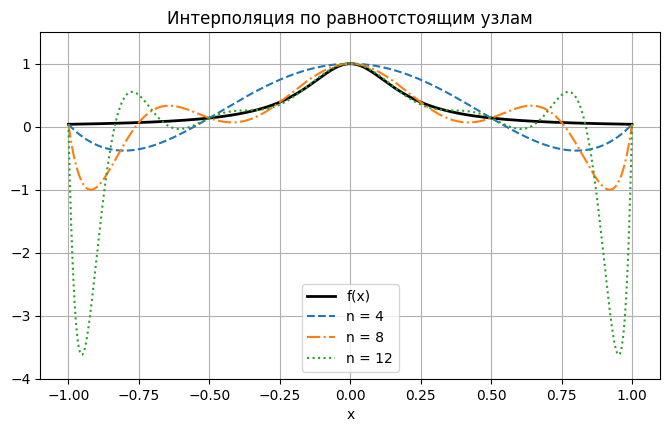

In [4]:
plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 12], ['--', '-.', ':']):
    x = np.linspace(a, b, n + 1)
    c = newton_coeff(x, runge(x))
    plt.plot(t, newton_eval(c, x, t), style, label=f'n = {n}')
plt.ylim(-4, 1.5)
plt.xlabel('x')
plt.title('Интерполяция по равноотстоящим узлам')
plt.legend()
plt.show()

In [5]:
print(' n    max|f - P_n|')
for n in range(2, 21, 2):
    x = np.linspace(a, b, n + 1)
    c = newton_coeff(x, runge(x))
    err = np.max(np.abs(newton_eval(c, x, t) - runge(t)))
    print(f'{n:2d}   {err:10.3e}')

 n    max|f - P_n|
 2    6.462e-01
 4    4.384e-01
 6    6.169e-01
 8    1.045e+00
10    1.916e+00


12    3.663e+00
14    7.195e+00
16    1.439e+01
18    2.919e+01
20    5.982e+01


> 🧑‍🏫 **Для преподавателя.** Перед запуском спросите аудиторию: «Что будет с графиком при увеличении n?». Большинство ответит, что приближение станет лучше. Не поднимайте n выше 20–25: при большом числе равноотстоящих узлов к феномену Рунге добавляются ошибки округления в разделённых разностях, и эффекты смешаются.

**Феномен Рунге.** При увеличении числа равноотстоящих узлов интерполяционный многочлен не сходится к функции Рунге: у краёв отрезка возникают осцилляции, амплитуда которых растёт с ростом $n$.

Объяснение даёт формула остаточного члена интерполяции:

$$f(x) - P_n(x) = \frac{f^{(n+1)}(\xi)}{(n+1)!}\,\omega_{n+1}(x), \qquad \omega_{n+1}(x) = \prod_{i=0}^{n}(x - x_i).$$

У функции Рунге производные растут очень быстро (быстрее, чем $(n+1)!$ компенсирует), а на равномерной сетке $|\omega_{n+1}(x)|$ велико у краёв отрезка.

Отсюда два пути:
1. Уменьшить $\max|\omega_{n+1}(x)|$ за счёт выбора узлов.
2. Не повышать степень многочлена, а перейти к локальной интерполяции.

## 3. Путь первый: узлы Чебышёва

Величина $\max_{[a,b]}|\omega_{n+1}(x)|$ минимальна, если в качестве узлов взять корни многочлена Чебышёва $T_{n+1}$, пересчитанные на отрезок $[a, b]$:

$$x_k = \frac{a + b}{2} + \frac{b - a}{2}\cos\frac{\pi(2k + 1)}{2(n + 1)}, \qquad k = 0, 1, \dots, n.$$

Узлы сгущаются к краям отрезка, как раз там, где на равномерной сетке возникали осцилляции.

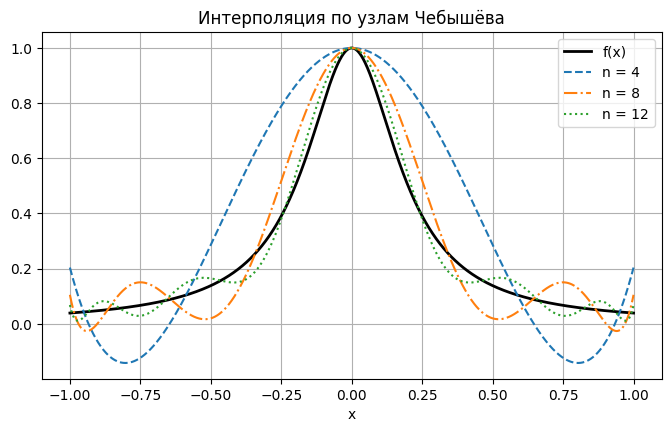

 n    max|f - P_n|
 2    6.006e-01
 4    4.020e-01
 6    2.642e-01
 8    1.708e-01
10    1.092e-01
12    6.922e-02
14    4.660e-02
16    3.261e-02
18    2.249e-02
20    1.533e-02


In [6]:
def chebyshev_nodes(a, b, n):
    # n + 1 узлов Чебышёва на [a, b]
    k = np.arange(n + 1)
    return 0.5 * (a + b) + 0.5 * (b - a) * np.cos(np.pi * (2 * k + 1) / (2 * (n + 1)))


plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 12], ['--', '-.', ':']):
    x = chebyshev_nodes(a, b, n)
    c = newton_coeff(x, runge(x))
    plt.plot(t, newton_eval(c, x, t), style, label=f'n = {n}')
plt.xlabel('x')
plt.title('Интерполяция по узлам Чебышёва')
plt.legend()
plt.show()

print(' n    max|f - P_n|')
for n in range(2, 21, 2):
    x = chebyshev_nodes(a, b, n)
    c = newton_coeff(x, runge(x))
    print(f'{n:2d}   {np.max(np.abs(newton_eval(c, x, t) - runge(t))):10.3e}')

**Дополнительно.** Важна не конкретная формула Чебышёва, а сгущение узлов к краям. Например, можно сгустить узлы с помощью гиперболического тангенса.

равномерные  max|f - P_n| = 3.663e+00
tanh         max|f - P_n| = 9.054e-02
Чебышёв      max|f - P_n| = 6.922e-02


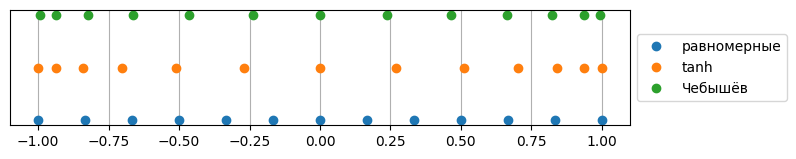

In [7]:
def tanh_nodes(a, b, n, beta=3.0):
    # Сгущение узлов к краям: отображение s(xi) растёт быстрее всего в центре,
    # поэтому в центре шаг большой, а у краёв маленький
    xi = np.linspace(0.0, 1.0, n + 1)
    s = 0.5 * (1.0 + np.tanh(beta * (xi - 0.5)) / np.tanh(0.5 * beta))
    return a + (b - a) * s


n = 12
fig, ax = plt.subplots(figsize=(8, 1.5))
for row, (name, x) in enumerate([('равномерные', np.linspace(a, b, n + 1)),
                                 ('tanh', tanh_nodes(a, b, n)),
                                 ('Чебышёв', chebyshev_nodes(a, b, n))]):
    ax.plot(x, 0 * x + row, 'o', label=name)
    c = newton_coeff(x, runge(x))
    print(f'{name:12s} max|f - P_n| = {np.max(np.abs(newton_eval(c, x, t) - runge(t))):.3e}')
ax.set_yticks([])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

**Почему узлов Чебышёва недостаточно?**

1. Узлы Чебышёва помогают, только если мы сами выбираем, где вычислять функцию. На практике данные часто заданы на фиксированной сетке: измерения, таблицы, результаты другого расчёта.
2. Глобальность: изменение одного значения $y_i$ меняет интерполяционный многочлен на всём отрезке (это увидим чуть ниже).
3. Многочлены высокой степени чувствительны к ошибкам в данных и к ошибкам округления.

Поэтому переходим ко второму пути — локальной интерполяции.

## 4. Путь второй: кусочно-линейная интерполяция

Самый простой вариант локальной интерполяции: на каждом отрезке $[x_{i-1}, x_i]$ соединяем соседние точки прямой:

$$g(x) = y_{i-1}\frac{x_i - x}{h_i} + y_i\frac{x - x_{i-1}}{h_i}, \qquad h_i = x_i - x_{i-1}.$$

Оценка погрешности для $f \in C^2[a, b]$ и $h = \max h_i$:

$$\max_{[a,b]}|f(x) - g(x)| \le \frac{h^2}{8}\max_{[a,b]}|f''(x)|.$$

Погрешность стремится к нулю при $h \to 0$ для любой дважды гладкой функции, никакого феномена Рунге нет. В `numpy` такая интерполяция уже реализована: `np.interp`.

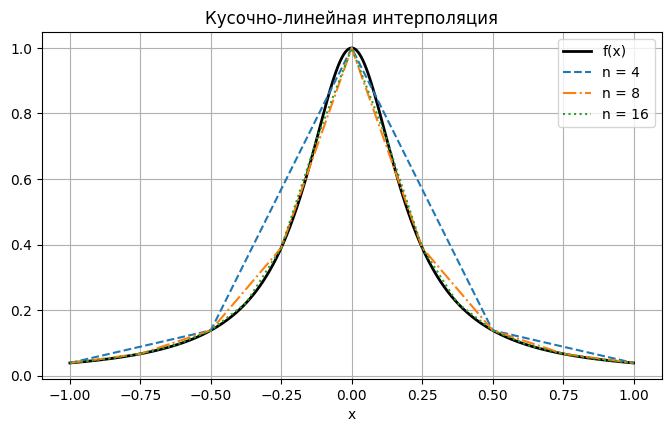

  n    max|f - g|
  4    1.802e-01
  8    6.390e-02
 16    5.355e-02
 32    2.070e-02
 64    5.846e-03
128    1.509e-03


In [8]:
plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 16], ['--', '-.', ':']):
    x = np.linspace(a, b, n + 1)
    plt.plot(t, np.interp(t, x, runge(x)), style, label=f'n = {n}')
plt.xlabel('x')
plt.title('Кусочно-линейная интерполяция')
plt.legend()
plt.show()

print('  n    max|f - g|')
for n in [4, 8, 16, 32, 64, 128]:
    x = np.linspace(a, b, n + 1)
    print(f'{n:3d}   {np.max(np.abs(np.interp(t, x, runge(x)) - runge(t))):10.3e}')

**Локальность.** Изменим одно значение $y_i$ в середине отрезка и посмотрим, как изменятся интерполяционный многочлен и кусочно-линейная интерполяция.

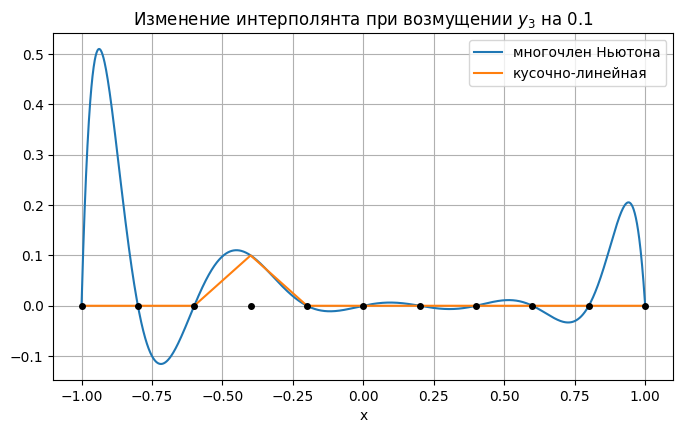

In [9]:
n = 10
x = np.linspace(a, b, n + 1)
y = runge(x)
y_pert = y.copy()
y_pert[3] += 0.1            # возмущаем одно значение

dP = newton_eval(newton_coeff(x, y_pert), x, t) - newton_eval(newton_coeff(x, y), x, t)
dL = np.interp(t, x, y_pert) - np.interp(t, x, y)

plt.plot(t, dP, label='многочлен Ньютона')
plt.plot(t, dL, label='кусочно-линейная')
plt.plot(x, 0 * x, 'ko', ms=4)
plt.xlabel('x')
plt.title('Изменение интерполянта при возмущении $y_3$ на 0.1')
plt.legend()
plt.show()

Изменение многочлена «расползается» на весь отрезок, а кусочно-линейная интерполяция меняется только на двух соседних отрезках.

**Недостаток кусочно-линейной интерполяции** — изломы в узлах: первая производная разрывна. Для многих задач это неприемлемо: например, если по интерполянту нужно вычислять производные (тепловой поток, скорость) или если нужна гладкая кривая в графике и геометрии.

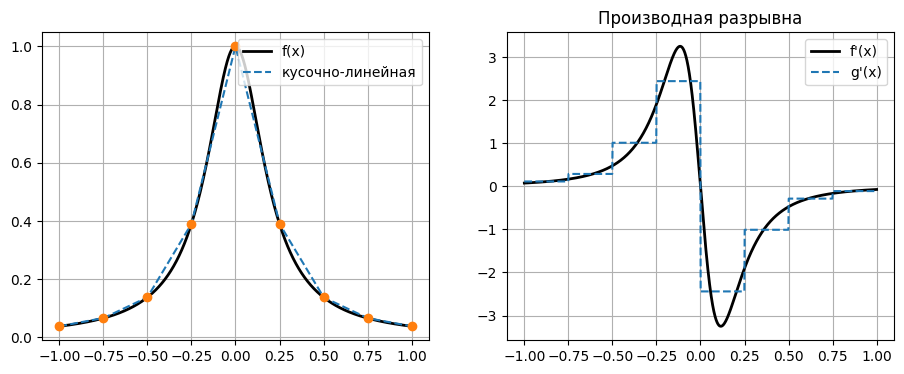

In [10]:
n = 8
x = np.linspace(a, b, n + 1)
g = np.interp(t, x, runge(x))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, runge(t), 'k', lw=2, label='f(x)')
ax[0].plot(t, g, '--', label='кусочно-линейная')
ax[0].plot(x, runge(x), 'o')
ax[0].legend()
ax[1].plot(t, np.gradient(runge(t), t), 'k', lw=2, label="f'(x)")
ax[1].plot(t, np.gradient(g, t), '--', label="g'(x)")
ax[1].legend()
ax[1].set_title('Производная разрывна')
plt.show()

## 5. Кубический сплайн

### Почему кубический?

Хотим сохранить локальность, но избавиться от изломов. Для этого берём на каждом отрезке многочлен более высокой степени и требуем непрерывности производных в узлах.

Кубический сплайн — минимальная степень, при которой непрерывна вторая производная, то есть кривизна. Именно тогда график выглядит гладким на глаз. Квадратичные сплайны требуют одного дополнительного условия на одном из концов и ведут себя несимметрично, поэтому на практике почти не используются.

Кстати, кусочно-линейная интерполяция — это тоже сплайн, сплайн первой степени.

### Определение

**Кубическим сплайном**, интерполирующим данные $(x_i, y_i)$, называется функция $S(x)$, такая что:
1. на каждом отрезке $[x_{i-1}, x_i]$, $i = 1, \dots, n$, $S(x)$ — многочлен степени не выше 3;
2. $S(x_i) = y_i$, $i = 0, \dots, n$;
3. $S(x) \in C^2[a, b]$, то есть $S$, $S'$ и $S''$ непрерывны во внутренних узлах $x_1, \dots, x_{n-1}$.

### Подсчёт условий

Неизвестных: по 4 коэффициента на каждый из $n$ отрезков, итого $4n$.

Условий:
- интерполяция на обоих концах каждого отрезка: $2n$;
- непрерывность $S'$ во внутренних узлах: $n - 1$;
- непрерывность $S''$ во внутренних узлах: $n - 1$.

Итого $4n - 2$ условия. **Не хватает двух условий** — их задают на концах отрезка. Это граничные условия.

> 🧑‍🏫 **Для преподавателя.** Прежде чем показать подсчёт, спросите студентов: «Сколько неизвестных? Сколько условий?». Пусть посчитают сами — это хороший момент вовлечения.

### Типы граничных условий

1. **Естественный (натуральный) сплайн:** $S''(a) = S''(b) = 0$.
2. **Закреплённый сплайн (clamped):** заданы производные на концах, $S'(a) = f'(a)$, $S'(b) = f'(b)$.
3. **Условие «not-a-knot»:** третья производная непрерывна в узлах $x_1$ и $x_{n-1}$. Тогда на первых двух и на последних двух отрезках сплайн — один и тот же многочлен, то есть $x_1$ и $x_{n-1}$ «не являются узлами». Это условие используется по умолчанию в `scipy.interpolate.CubicSpline`.
4. **Периодический сплайн:** $S'(a) = S'(b)$, $S''(a) = S''(b)$ (при $y_0 = y_n$). Нужен для периодических функций и замкнутых кривых.

### Чем хорош естественный сплайн

Он не требует знания производных $f$ на концах, а только значений в узлах. Кроме того, он обладает **свойством минимальной кривизны**: среди всех функций $g \in C^2[a, b]$, проходящих через заданные точки, естественный сплайн минимизирует функционал

$$\int_a^b \big(g''(x)\big)^2\,dx.$$

Физический смысл: так изгибается тонкая упругая линейка, закреплённая в точках (энергия изгиба пропорциональна интегралу квадрата кривизны). Английское слово *spline* и означало такую чертёжную линейку.

### Оценки погрешности

Если $f \in C^4[a, b]$ и сплайн закреплённый (или not-a-knot), то

$$\max_{[a,b]}|f - S| \le \frac{5}{384}h^4\max_{[a,b]}|f^{(4)}|, \qquad \max|f' - S'| = O(h^3), \qquad \max|f'' - S''| = O(h^2).$$

Для естественного сплайна всё не так просто, и это мы исследуем в конце семинара.

> 🧑‍🏫 **Для преподавателя.** Не раскрывайте заранее, что у естественного сплайна порядок у границ падает до O(h²), если f'' на концах не ноль. Это «открытие» студенты должны сделать сами в задаче 2. В итогах вернитесь к этому: в начале хвалили естественный сплайн, в конце нашли его слабое место.

## 6. Вывод системы уравнений: метод моментов

Обозначим **моменты** сплайна $M_i = S''(x_i)$, $i = 0, \dots, n$, и шаги $h_i = x_i - x_{i-1}$, $i = 1, \dots, n$.

**Шаг 1.** На отрезке $[x_{i-1}, x_i]$ сплайн — кубический многочлен, значит $S''$ линейна:

$$S''(x) = M_{i-1}\frac{x_i - x}{h_i} + M_i\frac{x - x_{i-1}}{h_i}.$$

Непрерывность $S''$ в узлах выполнена автоматически: в каждом узле $x_i$ оба соседних отрезка дают $M_i$.

**Шаг 2.** Интегрируем дважды и подбираем две константы интегрирования из условий $S(x_{i-1}) = y_{i-1}$, $S(x_i) = y_i$:

$$\boxed{S(x) = M_{i-1}\frac{(x_i - x)^3}{6h_i} + M_i\frac{(x - x_{i-1})^3}{6h_i} + \left(y_{i-1} - \frac{M_{i-1}h_i^2}{6}\right)\frac{x_i - x}{h_i} + \left(y_i - \frac{M_i h_i^2}{6}\right)\frac{x - x_{i-1}}{h_i}}$$

Интерполяционные условия теперь тоже выполнены автоматически. Осталось обеспечить непрерывность $S'$.

**Шаг 3.** Дифференцируем:

$$S'(x) = -M_{i-1}\frac{(x_i - x)^2}{2h_i} + M_i\frac{(x - x_{i-1})^2}{2h_i} + \frac{y_i - y_{i-1}}{h_i} - \frac{(M_i - M_{i-1})h_i}{6}.$$

Производная слева в узле $x_i$ (отрезок $i$) и справа (отрезок $i+1$):

$$S'(x_i - 0) = \frac{h_i}{6}M_{i-1} + \frac{h_i}{3}M_i + \frac{y_i - y_{i-1}}{h_i}, \qquad
S'(x_i + 0) = -\frac{h_{i+1}}{3}M_i - \frac{h_{i+1}}{6}M_{i+1} + \frac{y_{i+1} - y_i}{h_{i+1}}.$$

**Шаг 4.** Приравниваем и умножаем на 6. Получаем для $i = 1, \dots, n-1$:

$$\boxed{h_i M_{i-1} + 2(h_i + h_{i+1}) M_i + h_{i+1} M_{i+1} = 6\left(\frac{y_{i+1} - y_i}{h_{i+1}} - \frac{y_i - y_{i-1}}{h_i}\right)}$$

Это $n - 1$ уравнение на $n + 1$ неизвестную. Два недостающих уравнения дают граничные условия. Для естественного сплайна $M_0 = 0$, $M_n = 0$.

### Матричная форма (естественный сплайн)

Удобно оставить все $n+1$ неизвестных и записать граничные условия как первую и последнюю строки системы:

$$
\begin{pmatrix}
1 & 0 & & & & \\
h_1 & 2(h_1 + h_2) & h_2 & & & \\
 & h_2 & 2(h_2 + h_3) & h_3 & & \\
 & & \ddots & \ddots & \ddots & \\
 & & & h_{n-1} & 2(h_{n-1} + h_n) & h_n \\
 & & & & 0 & 1
\end{pmatrix}
\begin{pmatrix} M_0 \\ M_1 \\ M_2 \\ \vdots \\ M_{n-1} \\ M_n \end{pmatrix}
=
\begin{pmatrix} 0 \\ d_1 \\ d_2 \\ \vdots \\ d_{n-1} \\ 0 \end{pmatrix}.
$$

Плюс такой записи: для других граничных условий меняются только первая и последняя строки.

### Свойства матрицы

Матрица **трёхдиагональная**. Кроме того, у неё **строгое диагональное преобладание** по строкам:

$$2(h_i + h_{i+1}) > h_i + h_{i+1}, \qquad \text{а в граничных строках } 1 > 0.$$

По теореме Гершгорина все собственные значения лежат в кругах с центрами $a_{ii}$ и радиусами $\sum_{j \ne i}|a_{ij}| < |a_{ii}|$, поэтому ноль не является собственным значением. Следовательно, **матрица невырождена, и сплайн существует и единственен.** Диагональное преобладание также гарантирует устойчивость метода прогонки (раздел 8).

## 7. Реализация естественного сплайна

Сначала соберём матрицу явно и решим систему стандартным `np.linalg.solve`. Потом заменим его на прогонку.

**Внимание к индексам.** В формулах $h_i = x_i - x_{i-1}$, $i = 1, \dots, n$. В коде `h = np.diff(x)` даёт `h[0] = x[1] - x[0]`, то есть $h_i$ хранится в `h[i-1]`.

In [11]:
def natural_spline_system(x, y):
    # Матрица A и правая часть d системы для моментов естественного сплайна
    n = len(x) - 1
    h = np.diff(x)                 # h[i-1] = h_i = x_i - x_{i-1}
    A = np.zeros((n + 1, n + 1))
    d = np.zeros(n + 1)
    A[0, 0] = 1.0                  # M_0 = 0
    A[n, n] = 1.0                  # M_n = 0
    for i in range(1, n):
        A[i, i - 1] = h[i - 1]
        A[i, i]     = 2.0 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]
        d[i] = 6.0 * ((y[i + 1] - y[i]) / h[i] - (y[i] - y[i - 1]) / h[i - 1])
    return A, d

> 🧑‍🏫 **Для преподавателя.** Здесь уместна «запланированная ошибка»: напишите сначала `A[i, i-1] = h[i]` вместо `h[i-1]` (сдвиг индекса). На неравномерной сетке сплайн не пройдёт через узлы или будет заметно отличаться от scipy, на равномерной ошибку не видно вообще! Хороший повод обсудить, почему тесты надо делать на неравномерной сетке. Если не хотите рисковать временем — пропустите.

In [12]:
# Посмотрим на матрицу для небольшой неравномерной сетки
np.set_printoptions(precision=3, suppress=True, linewidth=120)
x = np.array([0.0, 0.3, 1.0, 1.4, 2.0])
A, d = natural_spline_system(x, np.sin(x))
print(A)

# Проверка строгого диагонального преобладания
diag = np.abs(np.diag(A))
off = np.sum(np.abs(A), axis=1) - diag
print('Диагональное преобладание:', np.all(diag > off))

[[1.  0.  0.  0.  0. ]
 [0.3 2.  0.7 0.  0. ]
 [0.  0.7 2.2 0.4 0. ]
 [0.  0.  0.4 2.  0.6]
 [0.  0.  0.  0.  1. ]]
Диагональное преобладание: True


### Вычисление сплайна в точках

Для каждой точки $t$ нужно найти номер отрезка $i$, такой что $x_{i-1} \le t < x_i$. Это делается бинарным поиском за $O(\log n)$. В `numpy` бинарный поиск для целого массива точек сразу реализован функцией `np.searchsorted`.

In [13]:
def spline_eval(x, y, M, t):
    # Значения кубического сплайна с моментами M в точках t
    t = np.asarray(t, dtype=float)
    # i такое, что x[i-1] <= t < x[i]; обрезаем, чтобы t = x_n попало в последний отрезок
    i = np.clip(np.searchsorted(x, t, side='right'), 1, len(x) - 1)
    h = x[i] - x[i - 1]
    left, right = x[i] - t, t - x[i - 1]
    return (M[i - 1] * left**3 + M[i] * right**3) / (6.0 * h) \
        + (y[i - 1] - M[i - 1] * h**2 / 6.0) * left / h \
        + (y[i] - M[i] * h**2 / 6.0) * right / h


def natural_spline(x, y):
    # Моменты естественного сплайна (пока через np.linalg.solve)
    A, d = natural_spline_system(x, y)
    return np.linalg.solve(A, d)


# Проверка: сплайн должен проходить через узлы
y = np.sin(x)
M = natural_spline(x, y)
print('max|S(x_i) - y_i| =', np.max(np.abs(spline_eval(x, y, M, x) - y)))

max|S(x_i) - y_i| = 0.0


### Сплайн для функции Рунге

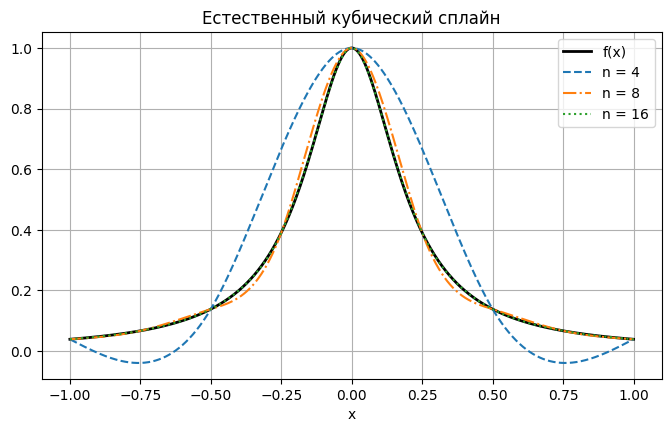

  n    сплайн       кусочно-линейная
  4    2.793e-01    1.802e-01
  8    5.607e-02    6.390e-02
 16    3.745e-03    5.355e-02
 32    6.555e-04    2.070e-02
 64    4.032e-05    5.846e-03
128    2.522e-06    1.509e-03


In [14]:
plt.plot(t, runge(t), 'k', lw=2, label='f(x)')
for n, style in zip([4, 8, 16], ['--', '-.', ':']):
    x = np.linspace(a, b, n + 1)
    y = runge(x)
    plt.plot(t, spline_eval(x, y, natural_spline(x, y), t), style, label=f'n = {n}')
plt.xlabel('x')
plt.title('Естественный кубический сплайн')
plt.legend()
plt.show()

print('  n    сплайн       кусочно-линейная')
for n in [4, 8, 16, 32, 64, 128]:
    x = np.linspace(a, b, n + 1)
    y = runge(x)
    e_s = np.max(np.abs(spline_eval(x, y, natural_spline(x, y), t) - runge(t)))
    e_l = np.max(np.abs(np.interp(t, x, y) - runge(t)))
    print(f'{n:3d}   {e_s:10.3e}   {e_l:10.3e}')

Никакого феномена Рунге: погрешность монотонно убывает с ростом числа узлов, и сплайн заметно точнее кусочно-линейной интерполяции при том же числе узлов.

### Сравнение со `scipy`

В `scipy.interpolate.CubicSpline` граничные условия задаются параметром `bc_type`:
- `'natural'` — естественный сплайн;
- `'clamped'` — нулевые первые производные на концах; произвольные производные задаются как `bc_type=((1, df_a), (1, df_b))`;
- `'not-a-knot'` — по умолчанию;
- `'periodic'` — периодический.

Объект `CubicSpline` можно вызывать как функцию, второй аргумент — порядок производной: `cs(t, 2)` даёт $S''(t)$.

In [15]:
x = np.sort(np.r_[a, b, np.random.default_rng(1).uniform(a, b, 9)])   # неравномерная сетка
y = runge(x)
M = natural_spline(x, y)
cs = CubicSpline(x, y, bc_type='natural')

print('Разница моментов:  ', np.max(np.abs(M - cs(x, 2))))
print('Разница значений:  ', np.max(np.abs(spline_eval(x, y, M, t) - cs(t))))

Разница моментов:   8.171241461241152e-14
Разница значений:   4.440892098500626e-16


## 8. Метод прогонки

Метод Гаусса для плотной матрицы требует $O(n^3)$ операций и $O(n^2)$ памяти. Для трёхдиагональной системы существует метод за $O(n)$ — **метод прогонки** (алгоритм Томаса).

Запишем систему в виде

$$a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i, \qquad i = 0, 1, \dots, n, \qquad a_0 = 0,\; c_n = 0.$$

Здесь $a_i$ — поддиагональ, $b_i$ — главная диагональ, $c_i$ — наддиагональ.

**Идея.** Ищем решение в виде $x_i = \alpha_{i+1}x_{i+1} + \beta_{i+1}$. Подставляя $x_{i-1} = \alpha_i x_i + \beta_i$ в $i$-е уравнение, получаем рекуррентные формулы.

**Прямой ход** (вычисляем прогоночные коэффициенты):

$$\alpha_1 = -\frac{c_0}{b_0}, \quad \beta_1 = \frac{d_0}{b_0}; \qquad
\alpha_{i+1} = -\frac{c_i}{b_i + a_i\alpha_i}, \quad \beta_{i+1} = \frac{d_i - a_i\beta_i}{b_i + a_i\alpha_i}, \quad i = 1, \dots, n-1.$$

**Обратный ход:**

$$x_n = \frac{d_n - a_n\beta_n}{b_n + a_n\alpha_n}; \qquad x_i = \alpha_{i+1}x_{i+1} + \beta_{i+1}, \quad i = n-1, \dots, 0.$$

**Устойчивость.** Если $|b_i| \ge |a_i| + |c_i|$ и хотя бы для одного $i$ неравенство строгое, то $|\alpha_i| \le 1$, знаменатели не обращаются в ноль и ошибки округления не нарастают. Для нашей матрицы это выполнено.

> 🧑‍🏫 **Для преподавателя.** На этом месте раздайте студенческую версию блокнота (в ней уже заполнено всё, что вы написали вживую). Задачи 1 и 2 — основные, на них уйдёт около 25 минут. Дополнительные задачи — для тех, кто справится быстрее.

---
# Задачи

### Задача 1. Метод прогонки

1. Реализуйте функцию `tridiag_solve(a, b, c, d)`, решающую трёхдиагональную систему методом прогонки. Массивы `a`, `b`, `c`, `d` имеют длину $n+1$, при этом `a[0]` и `c[n]` не используются.
2. Проверьте её на случайной системе с диагональным преобладанием, сравнив с `np.linalg.solve`.
3. Напишите функцию `natural_spline_tridiag(x, y)`, которая вычисляет моменты естественного сплайна с помощью прогонки, и сравните результат с `natural_spline`.
4. Сравните время работы `natural_spline` и `natural_spline_tridiag` при $n = 2000$. Объясните результат.

In [16]:
def tridiag_solve(a, b, c, d):
    # Метод прогонки для a_i x_{i-1} + b_i x_i + c_i x_{i+1} = d_i, i = 0..n
    n = len(d) - 1
    alpha = np.zeros(n + 1)
    beta = np.zeros(n + 1)
    # прямой ход: alpha[i], beta[i] связывают x_{i-1} = alpha[i] x_i + beta[i]
    alpha[1] = -c[0] / b[0]
    beta[1] = d[0] / b[0]
    for i in range(1, n):
        den = b[i] + a[i] * alpha[i]
        alpha[i + 1] = -c[i] / den
        beta[i + 1] = (d[i] - a[i] * beta[i]) / den
    # обратный ход
    x = np.zeros(n + 1)
    x[n] = (d[n] - a[n] * beta[n]) / (b[n] + a[n] * alpha[n])
    for i in range(n - 1, -1, -1):
        x[i] = alpha[i + 1] * x[i + 1] + beta[i + 1]
    return x

In [17]:
# Тест на случайной системе с диагональным преобладанием
rng = np.random.default_rng(0)
N = 50
a_ = rng.uniform(-1, 1, N); a_[0] = 0.0
c_ = rng.uniform(-1, 1, N); c_[-1] = 0.0
b_ = np.abs(a_) + np.abs(c_) + rng.uniform(0.5, 1.5, N)
d_ = rng.uniform(-1, 1, N)
A_full = np.diag(b_) + np.diag(a_[1:], -1) + np.diag(c_[:-1], 1)

print('Отличие от np.linalg.solve:', np.max(np.abs(tridiag_solve(a_, b_, c_, d_) - np.linalg.solve(A_full, d_))))

Отличие от np.linalg.solve: 1.1102230246251565e-16


In [18]:
def natural_spline_tridiag(x, y):
    # Моменты естественного сплайна методом прогонки (без построения полной матрицы)
    n = len(x) - 1
    h = np.diff(x)
    a_ = np.zeros(n + 1); b_ = np.ones(n + 1); c_ = np.zeros(n + 1); d_ = np.zeros(n + 1)
    a_[1:n] = h[:-1]
    b_[1:n] = 2.0 * (h[:-1] + h[1:])
    c_[1:n] = h[1:]
    d_[1:n] = 6.0 * (np.diff(y)[1:] / h[1:] - np.diff(y)[:-1] / h[:-1])
    return tridiag_solve(a_, b_, c_, d_)


x = np.sort(np.r_[a, b, np.random.default_rng(1).uniform(a, b, 9)])
y = runge(x)
print('Отличие от natural_spline:', np.max(np.abs(natural_spline_tridiag(x, y) - natural_spline(x, y))))

Отличие от natural_spline: 1.7763568394002505e-15


In [19]:
import time

x = np.linspace(0.0, 1.0, 2001)
y = np.sin(10 * x)
for func in [natural_spline, natural_spline_tridiag]:
    start = time.perf_counter()
    func(x, y)
    print(f'{func.__name__:24s} {time.perf_counter() - start:.4f} с')

natural_spline           0.1615 с
natural_spline_tridiag   0.0032 с


*Ответ к п. 4.* Прогонка требует $O(n)$ операций и $O(n)$ памяти, а `np.linalg.solve` для плотной матрицы — $O(n^3)$ операций и $O(n^2)$ памяти, к тому же сборка плотной матрицы в цикле тоже не бесплатна. Хотя прогонка написана на «медленном» Python, а `solve` вызывает оптимизированный LAPACK, при больших $n$ асимптотика побеждает.

### Задача 2. Исследование сходимости

Рассмотрим функцию $f(x) = e^x$ на отрезке $[0, 1]$.

1. Для $n = 4, 8, 16, \dots, 256$ равноотстоящих отрезков постройте три сплайна:
   - естественный (вашей функцией);
   - закреплённый с точными производными на концах: `CubicSpline(x, y, bc_type=((1, df_a), (1, df_b)))`;
   - not-a-knot: `CubicSpline(x, y)`.
2. Для каждого вычислите максимальную погрешность $\max|f - S|$ **на мелкой сетке** (не в узлах: там погрешность равна нулю!).
3. Постройте графики погрешности от шага $h$ в двойном логарифмическом масштабе (`plt.loglog`) и оцените порядок сходимости как наклон прямой: `np.polyfit(np.log(h), np.log(err), 1)[0]`.
4. Совпадают ли порядки для трёх типов граничных условий? Постройте график $|f(x) - S(x)|$ для естественного сплайна при $n = 32$. Где сосредоточена погрешность? Объясните результат.
5. Повторите исследование для $f(x) = \sin x$ на $[0, \pi]$. Что изменилось и почему?

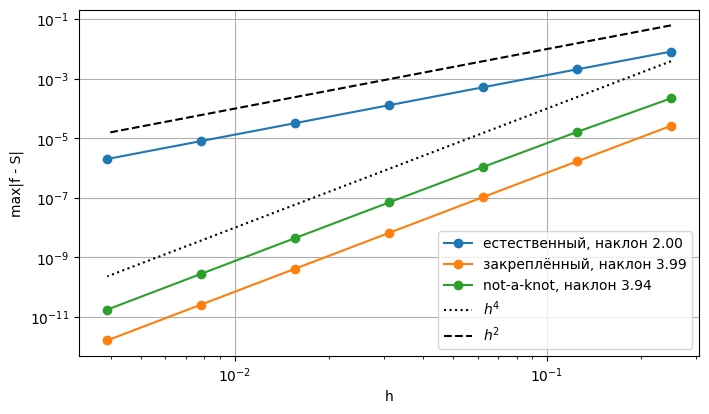

In [20]:
def convergence_study(f, df, xa, xb, ns):
    tt = np.linspace(xa, xb, 20001)
    hs, errs = [], {'естественный': [], 'закреплённый': [], 'not-a-knot': []}
    for n in ns:
        x = np.linspace(xa, xb, n + 1)
        y = f(x)
        hs.append((xb - xa) / n)
        errs['естественный'].append(np.max(np.abs(spline_eval(x, y, natural_spline_tridiag(x, y), tt) - f(tt))))
        cs = CubicSpline(x, y, bc_type=((1, df(xa)), (1, df(xb))))
        errs['закреплённый'].append(np.max(np.abs(cs(tt) - f(tt))))
        errs['not-a-knot'].append(np.max(np.abs(CubicSpline(x, y)(tt) - f(tt))))
    hs = np.array(hs)
    for name, e in errs.items():
        e = np.array(e)
        p = np.polyfit(np.log(hs), np.log(e), 1)[0]
        plt.loglog(hs, e, 'o-', label=f'{name}, наклон {p:.2f}')
    plt.loglog(hs, hs**4, 'k:', label='$h^4$')
    plt.loglog(hs, hs**2, 'k--', label='$h^2$')
    plt.xlabel('h')
    plt.ylabel('max|f - S|')
    plt.legend()
    plt.show()


ns = 2 ** np.arange(2, 9)
convergence_study(np.exp, np.exp, 0.0, 1.0, ns)

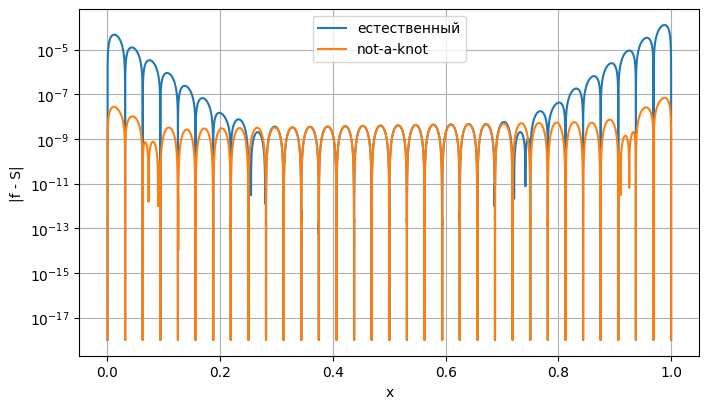

In [21]:
n = 32
x = np.linspace(0.0, 1.0, n + 1)
y = np.exp(x)
tt = np.linspace(0.0, 1.0, 20001)
plt.semilogy(tt, np.abs(spline_eval(x, y, natural_spline_tridiag(x, y), tt) - np.exp(tt)) + 1e-18, label='естественный')
plt.semilogy(tt, np.abs(CubicSpline(x, y)(tt) - np.exp(tt)) + 1e-18, label='not-a-knot')
plt.xlabel('x')
plt.ylabel('|f - S|')
plt.legend()
plt.show()

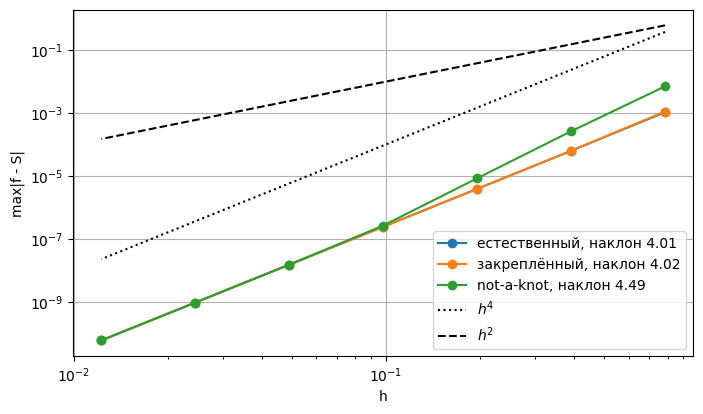

In [22]:
convergence_study(np.sin, np.cos, 0.0, np.pi, ns)

*Ответ к задаче 2.* Для $e^x$ на $[0, 1]$ закреплённый и not-a-knot сплайны дают порядок 4, а естественный — только 2. Условие $S''(a) = S''(b) = 0$ неверно для $e^x$ (у неё $f'' = e^x \ne 0$), и эта ошибка в граничном условии порождает погрешность $O(h^2)$ вблизи концов, которая быстро затухает вглубь отрезка (график при $n = 32$). Для $\sin x$ на $[0, \pi]$ вторая производная на концах действительно равна нулю, граничное условие естественного сплайна точное, и порядок 4 восстанавливается у всех трёх сплайнов.

Вывод: естественный сплайн хорош, когда о производных на концах ничего не известно, но если есть возможность, лучше использовать закреплённый сплайн или not-a-knot.

---
## Дополнительные задачи

### Задача 3. Закреплённый сплайн своими руками

Для закреплённого сплайна с заданными $S'(a) = f'_a$, $S'(b) = f'_b$ первая и последняя строки системы заменяются на

$$2h_1 M_0 + h_1 M_1 = 6\left(\frac{y_1 - y_0}{h_1} - f'_a\right), \qquad h_n M_{n-1} + 2h_n M_n = 6\left(f'_b - \frac{y_n - y_{n-1}}{h_n}\right).$$

1. Выведите эти формулы из выражения для $S'(x)$ в разделе 6.
2. Реализуйте функцию `clamped_spline(x, y, dfa, dfb)` на основе прогонки и сравните её с `CubicSpline(x, y, bc_type=((1, dfa), (1, dfb)))`.
3. Добавьте её в исследование сходимости из задачи 2.

In [23]:
def clamped_spline(x, y, dfa, dfb):
    n = len(x) - 1
    h = np.diff(x)
    a_ = np.zeros(n + 1); b_ = np.zeros(n + 1); c_ = np.zeros(n + 1); d_ = np.zeros(n + 1)
    a_[1:n] = h[:-1]
    b_[1:n] = 2.0 * (h[:-1] + h[1:])
    c_[1:n] = h[1:]
    d_[1:n] = 6.0 * (np.diff(y)[1:] / h[1:] - np.diff(y)[:-1] / h[:-1])
    b_[0], c_[0], d_[0] = 2.0 * h[0], h[0], 6.0 * ((y[1] - y[0]) / h[0] - dfa)
    a_[n], b_[n], d_[n] = h[-1], 2.0 * h[-1], 6.0 * (dfb - (y[n] - y[n - 1]) / h[-1])
    return tridiag_solve(a_, b_, c_, d_)


x = np.sort(np.r_[0.0, 1.0, np.random.default_rng(2).uniform(0, 1, 9)])
y = np.exp(x)
M = clamped_spline(x, y, 1.0, np.e)
cs = CubicSpline(x, y, bc_type=((1, 1.0), (1, np.e)))
print('Отличие от scipy:', np.max(np.abs(M - cs(x, 2))))

tt = np.linspace(0, 1, 20001)
hs, errs = [], []
for n in ns:
    x = np.linspace(0.0, 1.0, n + 1)
    y = np.exp(x)
    hs.append(1.0 / n)
    errs.append(np.max(np.abs(spline_eval(x, y, clamped_spline(x, y, 1.0, np.e), tt) - np.exp(tt))))
print('Порядок:', np.polyfit(np.log(hs), np.log(errs), 1)[0])

Отличие от scipy: 2.569056078982612e-13
Порядок: 3.990152569062098


### Задача 4. Насколько локален кубический сплайн?

Строго говоря, кубический сплайн не является локальным: система связывает все моменты, и изменение одного $y_i$ меняет сплайн на всём отрезке.

1. Возьмите $n = 20$ равноотстоящих отрезков на $[-1, 1]$ и данные функции Рунге. Измените одно значение $y_{10}$ на $0.1$.
2. Постройте в логарифмическом масштабе (`plt.semilogy`) модуль изменения сплайна $|\Delta S(x)|$ и интерполяционного многочлена $|\Delta P(x)|$.
3. Как ведёт себя $|\Delta S|$ при удалении от возмущённого узла? Оцените, во сколько раз уменьшается возмущение при переходе через один узел.

*Подсказка к п. 3.* Вдали от возмущения на равномерной сетке моменты удовлетворяют однородному уравнению $M_{i-1} + 4M_i + M_{i+1} = 0$. Найдите его решения вида $M_i = \lambda^i$.

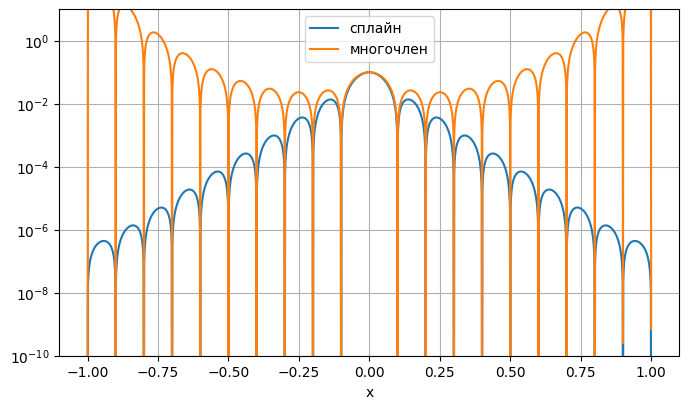

|dM_{i+1} / dM_i| справа от узла: [0.268 0.268 0.268 0.268 0.268]
2 - sqrt(3) = 0.2679491924311228


In [24]:
n = 20
x = np.linspace(a, b, n + 1)
y = runge(x)
y_pert = y.copy()
y_pert[10] += 0.1

dS = spline_eval(x, y_pert, natural_spline_tridiag(x, y_pert), t) - spline_eval(x, y, natural_spline_tridiag(x, y), t)
dP = newton_eval(newton_coeff(x, y_pert), x, t) - newton_eval(newton_coeff(x, y), x, t)

plt.semilogy(t, np.abs(dS) + 1e-18, label='сплайн')
plt.semilogy(t, np.abs(dP) + 1e-18, label='многочлен')
plt.semilogy(x, 0 * x + 1e-12, 'k|', ms=10)
plt.ylim(1e-10, 10)
plt.xlabel('x')
plt.legend()
plt.show()

# Отношение моментов возмущения в соседних узлах
dM = natural_spline_tridiag(x, y_pert) - natural_spline_tridiag(x, y)
print('|dM_{i+1} / dM_i| справа от узла:', np.abs(dM[12:17] / dM[11:16]))
print('2 - sqrt(3) =', 2 - np.sqrt(3))

*Ответ к задаче 4.* Характеристическое уравнение $\lambda^2 + 4\lambda + 1 = 0$ имеет корни $\lambda = -2 \pm \sqrt{3}$. Затухающее решение соответствует $|\lambda| = 2 - \sqrt{3} \approx 0.27$: возмущение уменьшается примерно в 3.7 раза на каждом отрезке и меняет знак. Сплайн «почти локален», а строго локальными являются B-сплайны.

### Задача 5. Неравномерная сетка

Функция $f(x) = \tanh(50x)$ на $[-1, 1]$ почти постоянна везде, кроме узкой области около нуля.

1. Постройте естественный сплайн по $n = 40$ равноотстоящим узлам и оцените погрешность.
2. Постройте сетку с тем же числом узлов, сгущённую к нулю, например $x_k = \dfrac{\sinh(\beta\xi_k)}{\sinh\beta}$, где $\xi_k$ — равномерная сетка на $[-1, 1]$. Подберите $\beta$, при котором погрешность минимальна.
3. Сравните графики обоих сплайнов вблизи нуля.

равномерная сетка: 0.2803838688194322
сгущённая сетка, лучшее beta = 4.50: 8.305708313782745e-05


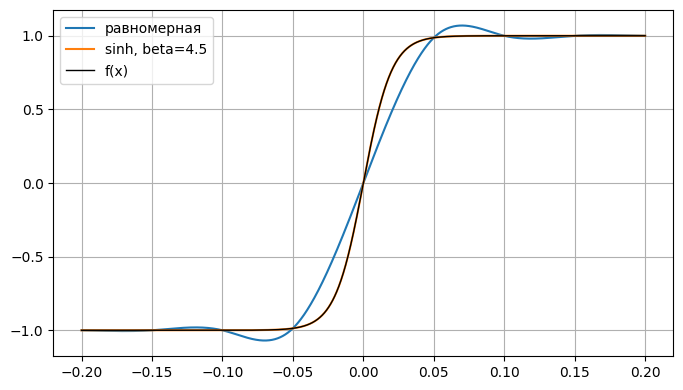

In [25]:
f5 = lambda x: np.tanh(50 * x)
n = 40
xi = np.linspace(-1, 1, n + 1)
tt = np.linspace(-1, 1, 20001)

def err_for(x):
    y = f5(x)
    return np.max(np.abs(spline_eval(x, y, natural_spline_tridiag(x, y), tt) - f5(tt)))

print('равномерная сетка:', err_for(xi))
betas = np.linspace(0.5, 6, 23)
errs = [err_for(np.sinh(bt * xi) / np.sinh(bt)) for bt in betas]
best = betas[np.argmin(errs)]
print(f'сгущённая сетка, лучшее beta = {best:.2f}:', min(errs))

zoom = np.linspace(-0.2, 0.2, 2001)
for name, x in [('равномерная', xi), (f'sinh, beta={best:.1f}', np.sinh(best * xi) / np.sinh(best))]:
    y = f5(x)
    plt.plot(zoom, spline_eval(x, y, natural_spline_tridiag(x, y), zoom), label=name)
plt.plot(zoom, f5(zoom), 'k', lw=1, label='f(x)')
plt.legend()
plt.show()

### Задача 6. Замкнутая гладкая кривая

Задайте 8–10 точек на плоскости, образующих замкнутый контур (последняя точка совпадает с первой). Постройте через них гладкую замкнутую кривую с помощью параметрического периодического сплайна:

1. введите параметр $s$ — накопленную длину ломаной, $s_0 = 0$, $s_k = s_{k-1} + |P_k - P_{k-1}|$;
2. постройте периодические сплайны $x(s)$ и $y(s)$: `CubicSpline(s, np.c_[px, py], bc_type='periodic')`;
3. нарисуйте кривую и исходные точки.

Почему параметр лучше выбирать как длину ломаной, а не просто номер точки?

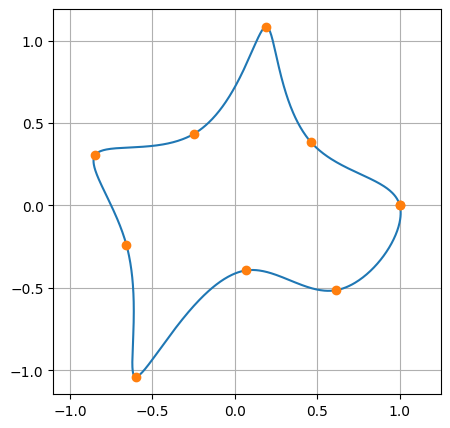

In [26]:
phi = np.linspace(0, 2 * np.pi, 10)[:-1]
r = np.array([1.0, 0.6, 1.1, 0.5, 0.9, 0.7, 1.2, 0.4, 0.8])
px = np.r_[r * np.cos(phi), r[0]]
py = np.r_[r * np.sin(phi), 0.0]

s = np.r_[0, np.cumsum(np.hypot(np.diff(px), np.diff(py)))]
cs = CubicSpline(s, np.c_[px, py], bc_type='periodic')
ss = np.linspace(0, s[-1], 1000)
curve = cs(ss)

plt.figure(figsize=(5, 5))
plt.plot(curve[:, 0], curve[:, 1])
plt.plot(px, py, 'o')
plt.axis('equal')
plt.show()

---
## Итоги

- Глобальная интерполяция многочленом высокой степени по равноотстоящим узлам может расходиться (феномен Рунге).
- Узлы Чебышёва решают проблему, но только если узлы можно выбирать.
- Локальная интерполяция сходится при уменьшении шага. Кусочно-линейная даёт порядок $O(h^2)$, но имеет изломы.
- Кубический сплайн — гладкая ($C^2$) кусочно-кубическая функция. Для его построения нужно решить трёхдиагональную систему с диагональным преобладанием, что делается методом прогонки за $O(n)$.
- Порядок точности сплайна $O(h^4)$ достигается при «правильных» граничных условиях. У естественного сплайна при $f''(a) \ne 0$ или $f''(b) \ne 0$ порядок падает до $O(h^2)$ из-за погрешности у концов.

---
## Домашнее задание

### ДЗ 1. Сплайн и монотонность: данные с фазовым переходом

При моделировании плавления часто используют зависимость удельной энтальпии $H$ от температуры $T$. При температуре плавления $T_m$ энтальпия скачком возрастает на величину скрытой теплоты $L$. Модельные данные (в безразмерных единицах):

$$H(T) = \begin{cases} c_s T, & T < T_m, \\ c_l T + L, & T \ge T_m, \end{cases} \qquad c_s = 1,\; c_l = 1.5,\; L = 5,\; T_m = 0.$$

1. Возьмите узлы $T_k$ — 21 равноотстоящая точка на $[-5, 5]$ — и постройте по данным кубический сплайн (`CubicSpline`) и монотонный эрмитов сплайн (`scipy.interpolate.PchipInterpolator`).
2. Нарисуйте оба интерполянта и их производные $dH/dT$ (эффективную теплоёмкость).
3. Есть ли у кубического сплайна участки, где $dH/dT < 0$? Какой физический смысл это имело бы? Почему у PCHIP такого не происходит?
4. Какой интерполянт вы бы выбрали для задачи о плавлении и почему?

### ДЗ 2. Максимум плотности воды

Плотность воды $\rho$ (кг/м³) при нормальном давлении:

| $T$, °C | 0 | 2 | 4 | 6 | 8 | 10 | 12 | 14 | 16 | 18 | 20 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| $\rho$ | 999.84 | 999.94 | 999.97 | 999.94 | 999.85 | 999.70 | 999.50 | 999.24 | 998.94 | 998.60 | 998.21 |

1. Постройте по таблице кубический сплайн (not-a-knot) и нарисуйте его вместе с табличными точками.
2. Найдите температуру максимума плотности как корень уравнения $S'(T) = 0$. Пока используйте `scipy.optimize.brentq`; на семинаре по нелинейным уравнениям мы решим эту задачу своими методами.
3. Сравните результат с известным значением $\approx 3.98$ °C. Сравните также с результатом для естественного сплайна.

### ДЗ 3. Точность производных сплайна

Для $f(x) = e^x$ на $[0, 1]$ и закреплённого сплайна численно определите порядки сходимости $\max|f' - S'|$ и $\max|f'' - S''|$. Согласуются ли они с теорией ($O(h^3)$ и $O(h^2)$)?

*Указание:* производные сплайна можно получить из `CubicSpline`: `cs(t, 1)`, `cs(t, 2)`, или вывести формулы для $S'$ и $S''$ через моменты.

### ДЗ 4 (по желанию). Сглаживающий сплайн

Сгенерируйте зашумлённые данные: $y_i = \sin(2\pi x_i) + \varepsilon_i$, $\varepsilon_i \sim \mathcal{N}(0, 0.1^2)$, 50 точек на $[0, 1]$. Сравните интерполяционный кубический сплайн и сглаживающий сплайн `scipy.interpolate.make_smoothing_spline`. Почему интерполировать зашумлённые данные — плохая идея? Как выглядят производные обоих сплайнов?

---
## Решения домашнего задания (только для преподавателя)

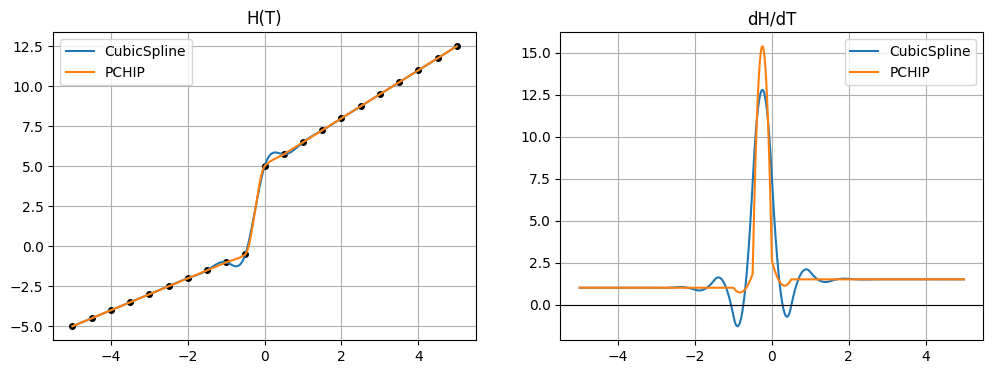

min dH/dT: CubicSpline = -1.2959648484647104 , PCHIP = 0.7222499999999998


In [27]:
from scipy.interpolate import PchipInterpolator

cs_, cl_, L_, Tm = 1.0, 1.5, 5.0, 0.0
H = lambda T: np.where(T < Tm, cs_ * T, cl_ * T + L_)
Tk = np.linspace(-5, 5, 21)
TT = np.linspace(-5, 5, 2001)
spl, pch = CubicSpline(Tk, H(Tk)), PchipInterpolator(Tk, H(Tk))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(Tk, H(Tk), 'ko', ms=4)
ax[0].plot(TT, spl(TT), label='CubicSpline')
ax[0].plot(TT, pch(TT), label='PCHIP')
ax[0].set_title('H(T)'); ax[0].legend()
ax[1].plot(TT, spl(TT, 1), label='CubicSpline')
ax[1].plot(TT, pch(TT, 1), label='PCHIP')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_title('dH/dT'); ax[1].legend()
plt.show()
print('min dH/dT: CubicSpline =', spl(TT, 1).min(), ', PCHIP =', pch(TT, 1).min())

*ДЗ 1.* Кубический сплайн на ступеньке осциллирует и даёт участки с $dH/dT < 0$, то есть отрицательную теплоёмкость — физически недопустимо, а в расчёте может привести к неустойчивости. PCHIP строит эрмитов кубический интерполянт с производными в узлах, подобранными так, чтобы сохранялась монотонность данных. Цена — только $C^1$-гладкость и более низкий порядок точности на гладких функциях.

not-a-knot : T_max = 3.969 °C, rho_max = 999.970
natural    : T_max = 3.902 °C, rho_max = 999.970


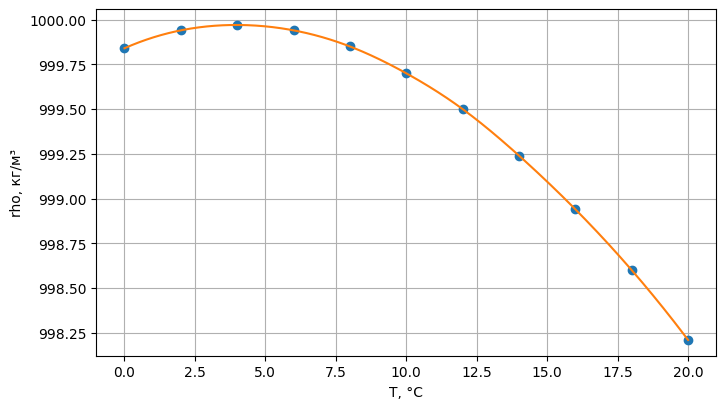

In [28]:
from scipy.optimize import brentq

T_tab = np.arange(0, 21, 2.0)
rho = np.array([999.84, 999.94, 999.97, 999.94, 999.85, 999.70, 999.50, 999.24, 998.94, 998.60, 998.21])
TT = np.linspace(0, 20, 1001)
for bc in ['not-a-knot', 'natural']:
    sp_ = CubicSpline(T_tab, rho, bc_type=bc)
    Tmax = brentq(lambda T: sp_(T, 1), 1.0, 8.0)
    print(f'{bc:11s}: T_max = {Tmax:.3f} °C, rho_max = {sp_(Tmax):.3f}')
plt.plot(T_tab, rho, 'o', TT, CubicSpline(T_tab, rho)(TT))
plt.xlabel('T, °C'); plt.ylabel('rho, кг/м³')
plt.show()

In [29]:
hs, e1, e2 = [], [], []
tt = np.linspace(0, 1, 20001)
for n in ns:
    x = np.linspace(0, 1, n + 1)
    c3 = CubicSpline(x, np.exp(x), bc_type=((1, 1.0), (1, np.e)))
    hs.append(1 / n)
    e1.append(np.max(np.abs(c3(tt, 1) - np.exp(tt))))
    e2.append(np.max(np.abs(c3(tt, 2) - np.exp(tt))))
print("порядок для S':", np.polyfit(np.log(hs), np.log(e1), 1)[0])
print("порядок для S'':", np.polyfit(np.log(hs), np.log(e2), 1)[0])

порядок для S': 2.9876883827462763
порядок для S'': 1.987258127759858


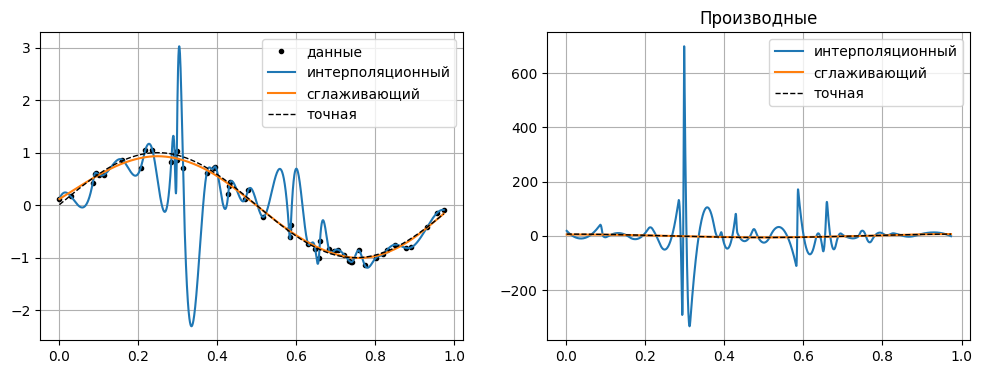

In [30]:
from scipy.interpolate import make_smoothing_spline

rng = np.random.default_rng(3)
xn = np.sort(rng.uniform(0, 1, 50))
yn = np.sin(2 * np.pi * xn) + rng.normal(0, 0.1, xn.size)
tt = np.linspace(xn[0], xn[-1], 2000)
interp, smooth = CubicSpline(xn, yn), make_smoothing_spline(xn, yn)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(xn, yn, 'k.', label='данные')
ax[0].plot(tt, interp(tt), label='интерполяционный')
ax[0].plot(tt, smooth(tt), label='сглаживающий')
ax[0].plot(tt, np.sin(2 * np.pi * tt), 'k--', lw=1, label='точная')
ax[0].legend()
ax[1].plot(tt, interp(tt, 1), label='интерполяционный')
ax[1].plot(tt, smooth(tt, 1), label='сглаживающий')
ax[1].plot(tt, 2 * np.pi * np.cos(2 * np.pi * tt), 'k--', lw=1, label='точная')
ax[1].set_title('Производные'); ax[1].legend()
plt.show()